# Labo 1 — Analyse de la décision lexicale

Une suite de lettres apparaît à l'écran : un mot fréquent (HF), un mot rare (LF) ou un pseudo-mot. La personne indique le plus vite possible
s'il s'agit d'un mot du français en touchant un côté d'une tablette (la *tape*). Elle fait 4 blocs assise et 4 blocs en marchant sur un tapis
roulant. L'EEG des 17 participants a déjà été prétraité par les notebooks 00, assis et en marche.

Nous examinerons le comportement, les ERP, leur topographie, leur amplitude et leur latence, l'interaction avec la marche et la relation entre
l'EEG et le comportement.

Les paramètres que vous pouvez modifier sont regroupés dans la section 0.4. Exécutez ensuite les cellules dans l'ordre.

## 0. Préparer l'analyse

La cellule 0.1 télécharge une seule fois les données du cours (1,7 Go) dans `tasks/brainwalk/`, à côté du notebook ; les notebooks 00, 01,
09, 10 et 11 utilisent ce même dossier. Dans Google Colab, elle installe aussi MNE et retélécharge les données à chaque nouvelle session.

In [1]:
# ---- 0.1 Les données : téléchargées une seule fois, dans tasks/brainwalk à côté du notebook --------------------------------------
import sys
import zipfile
import urllib.request
from pathlib import Path
import hashlib

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    !pip install -q mne
DOSSIER = Path('tasks/brainwalk')
ID_DRIVE = '19nnPiRuypz5fCPISybipdjxeop2EA_P8'               # le fichier labo1_donnees_2026.zip sur Google Drive
EMPREINTE = '21100ddabbc1ceba'                               # l'empreinte de manifest.json dans cette version des données


def donnees_a_jour():
    """True si DOSSIER contient cette version des données."""
    manifeste = DOSSIER / 'manifest.json'
    return manifeste.exists() and hashlib.sha256(manifeste.read_bytes()).hexdigest()[:16] == EMPREINTE


def progression(blocs, taille_bloc, total):
    """Affiche l'avancement du téléchargement, tous les 10 %."""
    if total > 0 and blocs * taille_bloc * 10 // total > (blocs - 1) * taille_bloc * 10 // total:
        print(f'  {min(100, 100 * blocs * taille_bloc // total)} %')


if not donnees_a_jour():
    archive = DOSSIER.parent / 'labo1_donnees_2026.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    print('Téléchargement des données depuis Google Drive (1,7 Go, quelques minutes) :')
    urllib.request.urlretrieve(f'https://drive.usercontent.google.com/download?id={ID_DRIVE}&export=download&confirm=t', archive, progression)
    if not zipfile.is_zipfile(archive):                      # Google Drive a renvoyé une page web au lieu du fichier
        archive.unlink()
        raise RuntimeError('Google Drive n\'a pas envoyé les données (trop de téléchargements aujourd\'hui ?). Réessayez plus tard.')
    with zipfile.ZipFile(archive) as z:
        z.extractall(DOSSIER.parent)
    archive.unlink()
print('Données :', DOSSIER, '(prêtes)' if donnees_a_jour() else '(INTROUVABLES : relancez cette cellule)')

Données : tasks\brainwalk (prêtes)


In [2]:
# ---- 0.2 Les bibliothèques -------------------------------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from scipy import stats

mne.set_log_level('ERROR')                                   # MNE n'affiche que les erreurs
print('MNE', mne.__version__)

MNE 1.13.2


### 0.3 Charger les données

Chaque participant a des époques autour du mot (-0,2 à 1,0 s) et autour de la tape (-0,8 à 0,2 s, avec la même ligne de base avant le mot),
pour les seuls essais utilisables : réponse correcte, temps de réaction normal, EEG sans artefact. Ce sont les essais que les notebooks 00
gardent, découpés jusqu'à 1,0 s dans leurs données nettoyées (dossier `pretraite_00/`). Chaque époque porte un nom `posture/type` :
pour les époques `ep` d'un participant, `ep['marche']` donne toutes les époques en marche et `ep['assis/LF']` les mots rares en position
assise. Le fichier `comportement/essais.csv` contient tous les essais.

Les mauvaises électrodes d'un enregistrement (notebook 00, étape 2) ne sont pas reconstruites : la colonne `mauvaises` des métadonnées en
donne la liste pour chaque époque. Elles ne sont pas des mesures : dans ce notebook, la valeur d'une région est la moyenne de ses seules
électrodes mesurées, époque par époque.

In [3]:
# ---- 0.3 Charger les données -----------------------------------------------------------------------------------------------------
epochs, epochs_tape = {}, {}                                 # participant -> ses époques autour du mot, et autour de la tape
for fichier in sorted((DOSSIER / 'pretraite_00').glob('sub-*_epo.fif')):
    participant = fichier.name.split('_')[0][4:]             # 'sub-P003_epo.fif' -> 'P003'
    epochs[participant] = mne.read_epochs(fichier, preload=True)
    fichier_tape = DOSSIER / 'pretraite_00' / 'tape' / f'sub-{participant}_tape_epo.fif'
    if fichier_tape.exists():
        epochs_tape[participant] = mne.read_epochs(fichier_tape, preload=True)
essais = pd.read_csv(DOSSIER / 'comportement' / 'essais.csv')
print(f'{len(epochs)} participants avec de l\'EEG ({len(epochs_tape)} avec les époques de la tape), {len(essais)} essais de comportement')
comptes = pd.DataFrame({p: ep.metadata.groupby(['posture', 'type']).size() for p, ep in epochs.items()}).T.fillna(0).astype(int)
comptes                                                      # le nombre d'époques par participant et condition

17 participants avec de l'EEG (17 avec les époques de la tape), 13600 essais de comportement


posture assis            marche           
type       HF  LF pseudo     HF  LF pseudo
P002       84  54    174     94  61    147
P003       97  72    187     80  66    155
P004       80  56    142     49  30     86
P006       92  80    170     45  28     74
P007       95  88    128     80  73    106
P008       96  72    160     73  71    144
P009       91  60    178     89  59    156
P010       87  76    163     74  66    133
P012       92  93    184     92  85    173
P014       96  64    178     70  50    140
P015       65  52    110     88  65    159
P016       92  66    153     89  72    161
P017       89  56    172     20  12     46
P018       95  67    185     92  56    175
P019       87  78    177     95  85    176
P020       88  59    173     46  24    102
P021       94  67    190     20   7     23

### 0.4 Choisir l'hypothèse et la composante

Écrivez votre hypothèse et vos prédictions avant de regarder les résultats.

- `'posture'` : marcher pendant la tâche crée une double tâche, qui pourrait ralentir les réponses et réduire ou retarder les ERP.
- `'frequence'` : un mot rare (LF) est plus difficile à reconnaître qu'un mot fréquent (HF) ; il devrait être reconnu plus lentement et
  produire une N400 plus négative.
- `'lexicalite'` : un pseudo-mot (par exemple *candre*) ne correspond à aucun mot connu ; il devrait produire des réponses plus lentes et une
  N400 plus négative que les mots.

Les fenêtres et les régions sont celles des notebooks 00. Elles viennent des analyses de groupe du projet Brain Walk, pas d'un
participant : la P2 là où la P2 du groupe est la plus nette, la N400 et la LPC sur une région centro-pariétale symétrique. Chaque
réponse se donne d'une main, et la moyenne de C3 avec C4 et de P3 avec P4 annule le potentiel moteur de cette main :

| Composante | Fenêtre (amplitude) | Recherche du pic | Région | Liée à |
|---|---|---|---|---|
| P2 | 140 à 220 ms après le mot | 100 à 300 ms | F3, Fz, F4, C3, Cz, C4 | l'attention et l'analyse visuelle du mot |
| N400 | 300 à 500 ms après le mot | 250 à 650 ms | C3, Cz, C4, P3, Pz, P4 | l'accès au sens ; plus négative quand il est difficile (Kutas et Federmeier, 2011) |
| LPC | -100 à 0 ms par rapport à la tape | -500 à +100 ms | C3, Cz, C4, P3, Pz, P4 | la décision ; elle culmine au moment de la réponse (Twomey et al., 2015) |
| LPC (mot) | 450 à 800 ms après le mot | 400 à 900 ms | C3, Cz, C4, P3, Pz, P4 | la même onde, étalée parce que la tape arrive à un moment différent à chaque essai |

Un clignement juste après la réponse peut modifier la LPC : vérifiez un effet sur la LPC avec `SANS_CLIGNEMENT = True`. Choisir une fenêtre
après avoir regardé les ERP rend le test trop optimiste : gardez celles du tableau, ou justifiez votre choix à l'avance.

In [4]:
# ---- 0.4 Vos choix ---------------------------------------------------------------------------------------------------------------
COMPOSANTES = {                # le tableau ci-dessus (ne pas modifier)
    'P2': dict(fenetre=(0.140, 0.220), region=['F3', 'Fz', 'F4', 'C3', 'Cz', 'C4'], polarite='pos', recherche=(0.100, 0.300), centre='mot'),
    'N400': dict(fenetre=(0.300, 0.500), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4'], polarite='neg', recherche=(0.250, 0.650), centre='mot'),
    'LPC': dict(fenetre=(-0.100, 0.0), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4'], polarite='pos', recherche=(-0.500, 0.100), centre='tape'),
    'LPC (mot)': dict(fenetre=(0.450, 0.800), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4'], polarite='pos', recherche=(0.400, 0.900), centre='mot'),
}

# Hypothèse
HYPOTHESE = 'posture'          # 'posture', 'frequence' ou 'lexicalite'
POSTURE = 'les deux'           # pour 'frequence' et 'lexicalite' : 'les deux', 'assis' ou 'marche'

# ERP
COMPOSANTE = 'P2'              # 'P2', 'N400', 'LPC' (autour de la tape) ou 'LPC (mot)'
FENETRE = COMPOSANTES[COMPOSANTE]['fenetre']   # ou votre fenêtre en secondes, par exemple (0.350, 0.450)
REGION = COMPOSANTES[COMPOSANTE]['region']     # ou d'autres électrodes, par exemple ['Cz', 'Pz']

# Options
SANS_CLIGNEMENT = False        # True : seulement les essais sans clignement entre le mot et la tape
EXIGER_MINIMUM = False         # True : sans les époques où la région a trop peu d'électrodes mesurées (section 0.5)

# Sections 5 et 6
EFFET = 'frequence'            # l'effet comparé entre les postures : 'frequence' (LF - HF) ou 'lexicalite' (pseudo-mots - mots)
COMPORTEMENT = 'TR (ms)'       # 'TR (ms)', 'Exactitude (%)' ou 'IES (ms)'
MESURE_EEG = 'amplitude (µV)'  # 'amplitude (µV)' ou 'latence (ms)'
VALEURS = 'difference'         # 'difference' (l'effet de chaque participant) ou une condition, par exemple 'assis'

In [5]:
# ---- 0.4 (suite) Préparer les époques selon vos choix (ne pas modifier) ----------------------------------------------------------
POLARITE = COMPOSANTES[COMPOSANTE]['polarite']               # le sens du pic pour la latence : 'pos' ou 'neg'
FENETRE_LATENCE = COMPOSANTES[COMPOSANTE]['recherche']       # où chercher le pic (section 4)
CENTRE = COMPOSANTES[COMPOSANTE]['centre']                   # le zéro des temps : 'mot' ou 'tape'
ZERO = 'le mot' if CENTRE == 'mot' else 'la tape'
NOM = COMPOSANTE if FENETRE == COMPOSANTES[COMPOSANTE]['fenetre'] else 'votre fenêtre'   # le nom affiché dans les figures
MIN_EPOQUES = 20                                             # un ERP de moins de 20 essais est trop bruité
MIN_MESUREES = {'P2': 4, 'N400': 4, 'LPC': 4, 'LPC (mot)': 4}   # le minimum d'électrodes mesurées de la région (section 0.5)
MINIMUM = MIN_MESUREES[COMPOSANTE] if REGION == COMPOSANTES[COMPOSANTE]['region'] else 1   # pour une autre région : au moins 1

if HYPOTHESE == 'posture':
    COND_A, COND_B = 'assis', 'marche'                       # les deux conditions comparées : B - A
    CHOIX_A, CHOIX_B = 'assis', 'marche'                     # comment choisir leurs époques
elif HYPOTHESE == 'frequence':
    COND_A, COND_B = 'HF', 'LF'
    CHOIX_A = 'HF' if POSTURE == 'les deux' else f'{POSTURE}/HF'
    CHOIX_B = 'LF' if POSTURE == 'les deux' else f'{POSTURE}/LF'
else:                                                        # 'lexicalite' : les pseudo-mots contre les mots (fréquents et rares)
    COND_A, COND_B = 'mots', 'pseudo-mots'
    debut = '' if POSTURE == 'les deux' else f'{POSTURE}/'
    CHOIX_A, CHOIX_B = [f'{debut}HF', f'{debut}LF'], f'{debut}pseudo'
COULEURS = {COND_A: '#2f6db5', COND_B: '#e0791d'}


def region_mesuree(ep, region):
    """Le signal de la région dans chaque époque (µV) : la moyenne des seules électrodes de la région mesurées dans cette époque, sans
    celles de la colonne mauvaises (NaN si aucune ne l'est). Rend aussi le nombre d'électrodes mesurées dans chaque époque."""
    x = ep.get_data(picks=region, units='uV')                                   # époques x électrodes x instants
    mesuree = np.array([[c not in str(r).split() for c in region] for r in ep.metadata['mauvaises']])   # époques x électrodes
    n = mesuree.sum(axis=1)
    signal = (x * mesuree[:, :, None]).sum(axis=1) / np.maximum(n, 1)[:, None]
    return np.where(n[:, None] > 0, signal, np.nan), n


if CENTRE == 'tape' and not epochs_tape:
    raise ValueError('Les époques de la tape (pretraite_00/tape/) sont introuvables : relancez la cellule 0.1, elle télécharge la dernière version des données')
EPOQUES = epochs_tape if CENTRE == 'tape' else epochs
if SANS_CLIGNEMENT:                                          # drop garde le nom des conditions, même vides
    EPOQUES = {p: ep.copy().drop(~ep.metadata['sans_clignement'].to_numpy(bool), reason='clignement') for p, ep in EPOQUES.items()}
    NOM += ' sans clignement'
minimum = MINIMUM if EXIGER_MINIMUM else 1                   # sans électrode mesurée, la région n'a pas de valeur dans l'époque
EPOQUES = {p: ep.copy().drop(region_mesuree(ep, REGION)[1] < minimum, reason='région') for p, ep in EPOQUES.items()}
if EXIGER_MINIMUM:
    NOM += f' ({MINIMUM}+ électrodes mesurées)'
print(f'Hypothèse « {HYPOTHESE} » : {COND_B} comparé à {COND_A} ; {NOM}, de {FENETRE[0] * 1000:.0f} à {FENETRE[1] * 1000:.0f} ms '
      f'(0 : {ZERO}), région {", ".join(REGION)}')

Hypothèse « posture » : marche comparé à assis ; P2, de 140 à 220 ms (0 : le mot), région F3, Fz, F4, C3, Cz, C4


### 0.5 Les électrodes mesurées

Vérifiez combien d'électrodes de chaque région sont réellement mesurées, pour chaque participant et chaque posture. Une région mal
échantillonnée rend l'estimation moins fiable. `EXIGER_MINIMUM = True` écarte les époques où la région a moins de 4 électrodes mesurées sur
6.

In [6]:
# ---- 0.5 Les électrodes mesurées dans chaque région ------------------------------------------------------------------------------
lignes_qc = []
for participant, ep in epochs.items():
    for posture in ('assis', 'marche'):
        md = ep.metadata[ep.metadata['posture'] == posture]
        if md.empty:
            continue
        listes = [str(r).split() for r in md['mauvaises']]       # les mauvaises électrodes de chaque époque
        ligne = {'participant': participant, 'posture': posture, 'époques': len(md),
                 'mauvaises': ' '.join(c for c in ep.ch_names if all(c in r for r in listes)) or '-'}
        for composante in ('P2', 'N400'):                     # la LPC a la région de la N400
            region = COMPOSANTES[composante]['region']
            n_mesurees = np.array([sum(c not in r for c in region) for r in listes])
            ligne[f'{composante} : mesurées (sur {len(region)})'] = round(n_mesurees.mean(), 1)
            ligne[f'{composante} : époques sous {MIN_MESUREES[composante]} (%)'] = round(100 * (n_mesurees < MIN_MESUREES[composante]).mean())
        lignes_qc.append(ligne)
qc = pd.DataFrame(lignes_qc).set_index(['participant', 'posture'])
qc

époques              mauvaises  P2 : mesurées (sur 6)  \
participant posture                                                          
P002        assis        312                     P7                    6.0   
            marche       302                  T7 P7                    6.0   
P003        assis        356                  P3 P7                    6.0   
            marche       301                  P3 P7                    6.0   
P004        assis        278                  P7 F8                    6.0   
            marche       165         C3 P7 O1 F7 P8                    5.0   
P006        assis        342                     P7                    6.0   
            marche       147                  P7 T8                    6.0   
P007        assis        311                  P7 F7                    6.0   
            marche       259               P7 F7 F8                    6.0   
P008        assis        328                  P7 Pz                    6.0   
            marche       288  C3 Fp1 P7 O1 O2 F7 Pz                    5.0   
P009        assis        329                  P7 Pz                    6.0   
            marche       304   C3 F3 T7 P7 O1 O2 P8                    4.0   
P010        assis        326                     P7                    6.0   
            marche       273                     P7                    6.0   
P012        assis        369                  F4 P7                    5.0   
            marche       350                  F4 P7                    5.0   
P014        assis        338                     P7                    6.0   
            marche       260         P3 C3 Cz P7 O2                    4.0   
P015        assis        227                     P7                    6.0   
            marche       312         Fz P4 P7 O1 O2                    5.0   
P016        assis        311              Fp2 P7 F7                    6.0   
            marche       322               P7 O1 O2                    6.0   
P017        assis        317                     P7                    6.0   
            marche        78            C3 P7 O1 O2                    5.0   
P018        assis        347         C4 P7 O1 O2 F7                    5.0   
            marche       323            C4 P7 O2 F8                    5.0   
P019        assis        342                     P7                    6.0   
            marche       356                  P7 Pz                    6.0   
P020        assis        320                     F7                    6.0   
            marche       172                     O1                    6.0   
P021        assis        351               Cz O1 O2                    5.0   
            marche        50      C3 P4 Cz O1 O2 F7                    4.0   

                     P2 : époques sous 4 (%)  N400 : mesurées (sur 6)  \
participant posture                                                     
P002        assis                          0                      6.0   
            marche                         0                      6.0   
P003        assis                          0                      5.0   
            marche                         0                      5.0   
P004        assis                          0                      6.0   
            marche                         0                      5.0   
P006        assis                          0                      6.0   
            marche                         0                      6.0   
P007        assis                          0                      6.0   
            marche                         0                      6.0   
P008        assis                          0                      5.0   
            marche                         0                      4.0   
P009        assis                          0                      5.0   
            marche                         0                      5.0   
P010        assis                          0

## 1. Comportement

Pour chaque participant et chaque condition, on calcule le temps de réaction (TR) moyen des réponses correctes, l'exactitude (le pourcentage
de réponses correctes, sans les omissions) et l'IES (TR / exactitude). L'IES combine vitesse et justesse, mais il n'est fiable que si
l'exactitude est élevée (plus de 90 % environ). Les deux conditions sont comparées par un test t apparié ; dz, la différence moyenne divisée
par l'écart-type des différences, donne la taille de l'effet (0,2 petit, 0,5 moyen, 0,8 grand).

In [7]:
# ---- 1.1 Les moyennes de chaque participant --------------------------------------------------------------------------------------
if HYPOTHESE == 'posture':
    choisis = essais.assign(condition=essais['posture'])     # tous les essais, mots et pseudo-mots
elif HYPOTHESE == 'frequence':
    choisis = essais[essais['type'].isin(['HF', 'LF'])]
    if POSTURE != 'les deux':
        choisis = choisis[choisis['posture'] == POSTURE]
    choisis = choisis.assign(condition=choisis['type'])
else:
    choisis = essais if POSTURE == 'les deux' else essais[essais['posture'] == POSTURE]
    choisis = choisis.assign(condition=np.where(choisis['type'] == 'pseudo', 'pseudo-mots', 'mots'))
tr = choisis[choisis['tr_valide']].groupby(['participant', 'condition'])['tr_ms'].mean()   # réponse correcte, 250 ms ou plus, pas aberrante
exactitude = choisis.groupby(['participant', 'condition'])['correct'].mean()              # une omission (correct vide) ne compte pas
comport = pd.DataFrame({'TR (ms)': tr, 'Exactitude (%)': 100 * exactitude}).reset_index()
comport['IES (ms)'] = comport['TR (ms)'] / (comport['Exactitude (%)'] / 100)
comport.round(1)

,participant,condition,TR (ms),Exactitude (%),IES (ms)
0,P002,assis,687.4,82.8,830.6
1,P002,marche,706.5,80.0,883.1
2,P003,assis,685.1,91.2,750.8
3,P003,marche,704.6,90.5,778.5
4,P004,assis,820.1,77.7,1055.6
5,P004,marche,818.6,85.2,960.7
6,P006,assis,658.9,89.7,734.4
7,P006,marche,652.9,84.8,770.4
8,P007,assis,665.6,80.2,829.4
9,P007,marche,720.8,81.6,883.4


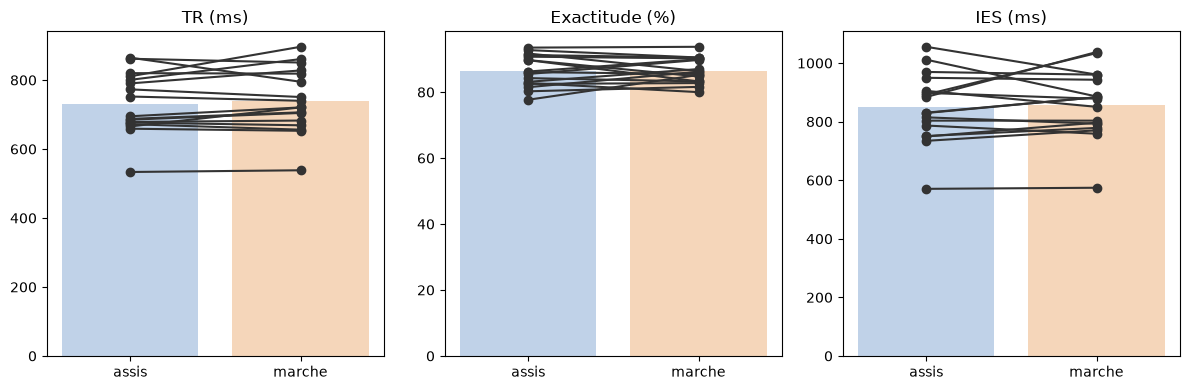

TR (ms) : assis 731.0, marche 740.7 ; t(16) = 1.10, p = 0.288, dz = 0.27
Exactitude (%) : assis 86.4, marche 86.5 ; t(16) = 0.09, p = 0.933, dz = 0.02
IES (ms) : assis 849.2, marche 858.3 ; t(16) = 0.53, p = 0.606, dz = 0.13


In [8]:
# ---- F1 : le comportement --------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
resultats = []
for ax, mesure in zip(axes, ['TR (ms)', 'Exactitude (%)', 'IES (ms)']):
    large = comport.pivot(index='participant', columns='condition', values=mesure)[[COND_A, COND_B]].dropna()   # qui a les deux conditions
    ax.bar([0, 1], large.mean(), color=[COULEURS[COND_A], COULEURS[COND_B]], alpha=0.3)       # la moyenne du groupe
    ax.plot([0, 1], large.T.to_numpy(), color='0.2', marker='o')                               # un trait par participant
    ax.set(xticks=[0, 1], xticklabels=[COND_A, COND_B], title=mesure)
    t, p = stats.ttest_rel(large[COND_B], large[COND_A])
    difference = large[COND_B] - large[COND_A]
    resultats.append(f'{mesure} : {COND_A} {large[COND_A].mean():.1f}, {COND_B} {large[COND_B].mean():.1f} ; '
                     f't({len(large) - 1}) = {t:.2f}, p = {p:.3f}, dz = {difference.mean() / difference.std(ddof=1):.2f}')
plt.tight_layout()
plt.show()
print('\n'.join(resultats))

*La marche modifie-t-elle le temps de réaction ? Les mots rares (`HYPOTHESE = 'frequence'`) sont-ils reconnus plus lentement ?*

## 2. ERP

L'ERP d'un participant est la moyenne de ses époques dans une condition, et l'ERP du groupe la moyenne des ERP des participants. Les figures
montrent la région choisie ; la bande colorée est l'intervalle de confiance à 95 % entre participants. Un participant qui a moins de 20 essais
dans une condition est laissé de côté.

In [9]:
# ---- 2.1 L'ERP de chaque participant dans chaque condition -----------------------------------------------------------------------
erp_A, erp_B, onde_A, onde_B, participants = [], [], [], [], []   # par participant : l'ERP de chaque électrode, et celui de la région
for participant, ep in EPOQUES.items():
    e_a, e_b = ep[CHOIX_A], ep[CHOIX_B]
    if len(e_a) < MIN_EPOQUES or len(e_b) < MIN_EPOQUES:
        print(f'{participant} laissé de côté : {len(e_a)} essais {COND_A}, {len(e_b)} essais {COND_B}')
        continue
    for e, erp, onde in ((e_a, erp_A, onde_A), (e_b, erp_B, onde_B)):
        # chaque électrode : la moyenne des seuls essais où elle est mesurée (NaN s'ils sont trop peu nombreux)
        mesuree = np.array([[c not in str(r).split() for c in e.ch_names] for r in e.metadata['mauvaises']])   # essais x électrodes
        compte = mesuree.sum(axis=0)
        moyenne = np.where(mesuree[:, :, None], e.get_data(), 0.0).sum(axis=0) / np.maximum(compte, 1)[:, None]
        moyenne[compte < MIN_EPOQUES] = np.nan
        erp.append(mne.EvokedArray(moyenne, e.info, tmin=e.tmin, nave=len(e)))
        # la région : un Evoked à un seul canal, la moyenne de ses électrodes mesurées dans chaque essai (MNE travaille en volts)
        info_region = mne.create_info(['région'], e.info['sfreq'], 'eeg')
        onde.append(mne.EvokedArray(region_mesuree(e, REGION)[0].mean(axis=0, keepdims=True) * 1e-6, info_region, tmin=e.tmin, nave=len(e)))
    participants.append(participant)
print(f'{len(participants)} participants : {", ".join(participants)}')

17 participants : P002, P003, P004, P006, P007, P008, P009, P010, P012, P014, P015, P016, P017, P018, P019, P020, P021


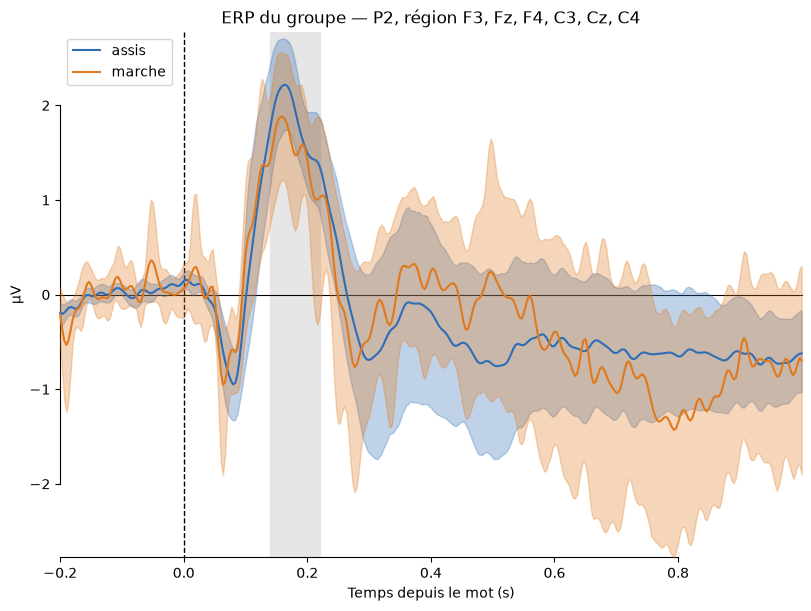

In [10]:
# ---- F2 : les ERP du groupe ------------------------------------------------------------------------------------------------------
figure = mne.viz.plot_compare_evokeds({COND_A: onde_A, COND_B: onde_B}, picks='région', ci=0.95, colors=COULEURS, show_sensors=False,
                                      title=f'ERP du groupe — {NOM}, région {", ".join(REGION)}', show=False)[0]
ax = figure.axes[0]
ax.axvspan(*FENETRE, color='0.9', zorder=0)                  # la fenêtre de la composante
ax.set_xlabel(f'Temps depuis {ZERO} (s)')
plt.show()

### 2.2 Onde de différence et test par amas

L'onde de différence (par exemple marche - assis) est calculée pour chaque participant, puis moyennée. Tester chaque instant séparément
multiplie les comparaisons : les zones grises, où un test t donne p < .05 à cet instant, sont seulement descriptives. Le test par amas évalue
des groupes d'instants voisins par permutation (Maris et Oostenveld, 2007) ; un amas significatif apparaît en vert. Il indique une différence
dans cet intervalle, sans en fixer précisément le début ni la fin.

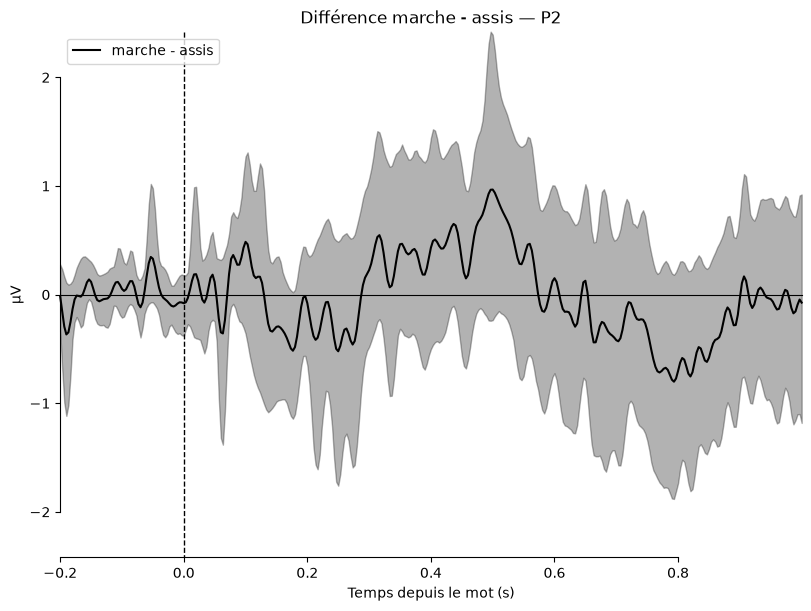

Amas : aucun


In [11]:
# ---- F3 : l'onde de différence et le test par amas -------------------------------------------------------------------------------
from mne.stats import permutation_cluster_1samp_test

difference = [mne.combine_evoked([b, a], weights=[1, -1]) for a, b in zip(onde_A, onde_B)]   # B - A, pour chaque participant
X = np.array([d.data[0] for d in difference]) * 1e6           # participants x instants (µV)
seuil = stats.t.ppf(0.975, len(X) - 1)                        # forme les amas : le t d'un test bilatéral à p < .05
_, amas, p_amas, _ = permutation_cluster_1samp_test(X, threshold=seuil, n_permutations=1024, tail=0, out_type='mask', seed=97)
figure = mne.viz.plot_compare_evokeds({f'{COND_B} - {COND_A}': difference}, picks='région', ci=0.95, colors=['k'], show_sensors=False,
                                      title=f'Différence {COND_B} - {COND_A} — {NOM}', show=False)[0]
ax = figure.axes[0]
temps = difference[0].times
for masque, p in zip(amas, p_amas):                           # vert : amas significatif ; gris : p < .05 instant par instant seulement
    ax.axvspan(temps[masque][0], temps[masque][-1], color='C2' if p < 0.05 else '0.5', alpha=0.3, lw=0, zorder=0)
ax.set_xlabel(f'Temps depuis {ZERO} (s)')
plt.show()
ordre = np.argsort([temps[m][0] for m in amas])                # les amas dans l'ordre du temps
print('Amas :', ', '.join(f'{temps[amas[k]][0] * 1000:.0f} à {temps[amas[k]][-1] * 1000:.0f} ms (p = {p_amas[k]:.3f})' for k in ordre) or 'aucun')

*Les deux ERP se séparent-ils dans la fenêtre choisie, et le test par amas le confirme-t-il ?*

## 3. Topographie

Les cartes montrent l'amplitude moyenne dans la fenêtre, vue de dessus (le nez en haut), sur une échelle commune ; les points noirs marquent
la région choisie. À chaque électrode, la carte du groupe moyenne les participants qui l'ont mesurée ; une électrode mesurée chez moins de 3
participants, ou de la moitié d'entre eux, reste un cercle vide. Sur la carte de la différence, les ronds blancs marquent les électrodes où un
test t apparié donne p < .05, sans correction pour le nombre de tests.

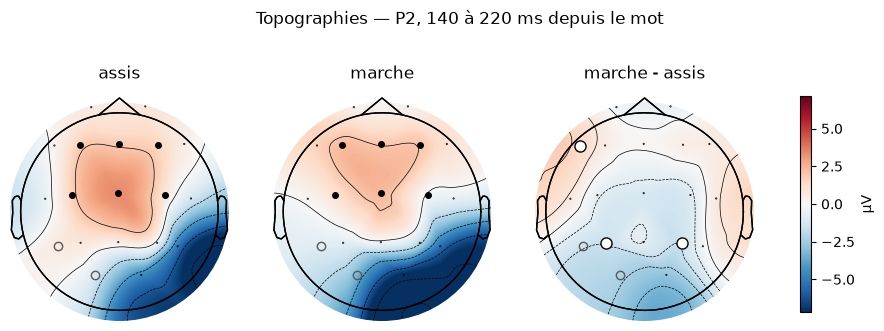

Électrodes à p < .05 (non corrigé) : P3, P4, F7


In [12]:
# ---- F4 : les topographies -------------------------------------------------------------------------------------------------------
from matplotlib.colors import ListedColormap                 # une carte de couleurs transparente, pour les cercles vides
noms_ch = np.array(erp_A[0].ch_names)
valeurs_A = np.array([e.copy().crop(*FENETRE).data.mean(axis=1) for e in erp_A]) * 1e6   # participants x électrodes (µV ; NaN : pas mesurée)
valeurs_B = np.array([e.copy().crop(*FENETRE).data.mean(axis=1) for e in erp_B]) * 1e6
deux = np.isfinite(valeurs_A) & np.isfinite(valeurs_B)       # le participant a mesuré l'électrode dans les deux conditions
vue = deux.sum(axis=0) >= max(3, len(participants) / 2)      # la règle du projet : au moins 3 participants, et la moitié d'entre eux
visibles = np.flatnonzero(vue)
cartes = [np.array([valeurs[deux[:, j], j].mean() for j in visibles]) for valeurs in (valeurs_A, valeurs_B, valeurs_B - valeurs_A)]
p_electrodes = np.array([stats.ttest_rel(valeurs_B[deux[:, j], j], valeurs_A[deux[:, j], j]).pvalue for j in visibles])   # un test par électrode
limite = max(np.abs(c).max() for c in cartes)                # la même échelle pour les trois cartes
info_vue = mne.pick_info(erp_A[0].info, visibles)
masques = [np.isin(noms_ch[vue], REGION), np.isin(noms_ch[vue], REGION), p_electrodes < 0.05]
styles = [dict(marker='o', markerfacecolor='k', markersize=4)] * 2 + [dict(marker='o', markerfacecolor='w', markeredgecolor='k', markersize=8)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, carte, masque, style, titre in zip(axes, cartes, masques, styles, [COND_A, COND_B, f'{COND_B} - {COND_A}']):
    image, _ = mne.viz.plot_topomap(carte, info_vue, axes=ax, show=False, vlim=(-limite, limite), cmap='RdBu_r', mask=masque, mask_params=style)
    if not vue.all():                                        # les électrodes trop peu mesurées : des cercles vides, sans valeur
        mne.viz.plot_topomap(np.zeros(len(noms_ch)), erp_A[0].info, axes=ax, show=False, vlim=(-1, 1), cmap=ListedColormap([(0, 0, 0, 0)]),
                             contours=0, sensors=False, mask=~vue, mask_params=dict(marker='o', markerfacecolor='none', markeredgecolor='0.35', markersize=6))
    ax.set_title(titre)
fig.colorbar(image, ax=axes, shrink=0.7, label='µV')
fig.suptitle(f'Topographies — {NOM}, {FENETRE[0] * 1000:.0f} à {FENETRE[1] * 1000:.0f} ms depuis {ZERO}')
plt.show()
print('Électrodes à p < .05 (non corrigé) :', ', '.join(noms_ch[vue][p_electrodes < 0.05]) or 'aucune')

*La topographie de la différence correspond-elle à la composante attendue ?*

## 4. Amplitude et latence

Pour chaque participant et chaque condition, on mesure deux valeurs sur l'ERP de la région : l'amplitude moyenne dans la fenêtre, qui est la
mesure principale, et la latence du pic, cherché dans une fenêtre plus large. La latence du pic est plus sensible au bruit que l'amplitude
moyenne. Pour la N400, une amplitude plus négative correspond à une onde plus grande.

La SME (*standardized measurement error* ; Luck et al., 2021) estime la précision de l'amplitude d'un participant : SME = écart-type des
amplitudes essai par essai / √n, où n est le nombre d'essais. Une SME plus grande indique une estimation moins précise.

In [13]:
# ---- 4.1 Amplitude, latence et SME de chaque participant -------------------------------------------------------------------------
lignes = []
for participant, a, b in zip(participants, onde_A, onde_B):
    for condition, onde, choix in ((COND_A, a, CHOIX_A), (COND_B, b, CHOIX_B)):
        amplitude = onde.copy().crop(*FENETRE).data.mean() * 1e6
        # strict=False : le point le plus haut (ou le plus bas) de la fenêtre, quel que soit son signe
        _, latence = onde.get_peak(tmin=FENETRE_LATENCE[0], tmax=FENETRE_LATENCE[1], mode=POLARITE, strict=False)
        par_essai = region_mesuree(EPOQUES[participant][choix].copy().crop(*FENETRE), REGION)[0].mean(axis=1)   # l'amplitude de chaque essai
        lignes.append({'participant': participant, 'condition': condition, 'amplitude (µV)': amplitude, 'latence (ms)': latence * 1000,
                       'SME (µV)': par_essai.std(ddof=1) / np.sqrt(len(par_essai)), 'essais': len(par_essai)})
mesures_eeg = pd.DataFrame(lignes)
mesures_eeg.round(2)

,participant,condition,amplitude (µV),latence (ms),SME (µV),essais
0,P002,assis,2.86,143.33,0.30,312
1,P002,marche,3.60,143.33,0.43,302
2,P003,assis,1.96,266.67,0.16,356
3,P003,marche,2.27,230.00,0.59,301
4,P004,assis,3.43,140.00,0.26,278
5,P004,marche,-0.40,196.67,0.98,165
6,P006,assis,1.25,176.67,0.40,342
7,P006,marche,1.62,176.67,0.85,147
8,P007,assis,2.02,170.00,0.21,311
9,P007,marche,2.46,166.67,0.53,259


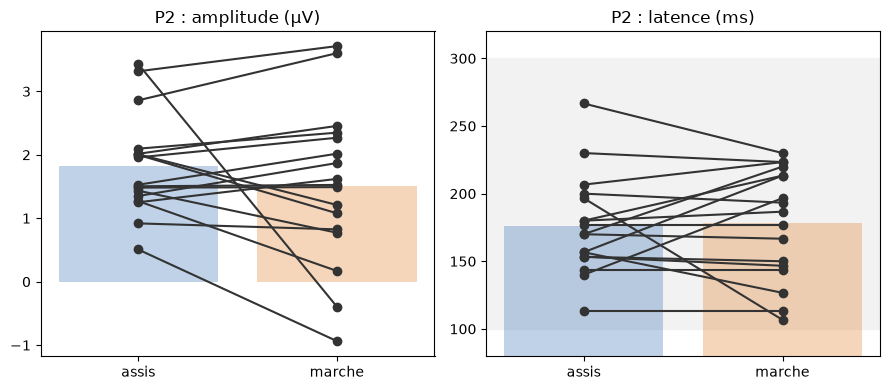

P2 amplitude (µV) : assis 1.82, marche 1.51 ; t(16) = -1.15, p = 0.266, dz = -0.28
P2 latence (ms) : assis 176.08, marche 178.24 ; t(16) = 0.25, p = 0.808, dz = 0.06


In [14]:
# ---- F6 : amplitude et latence ---------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
resultats = []
for ax, mesure in zip(axes, ['amplitude (µV)', 'latence (ms)']):
    large = mesures_eeg.pivot(index='participant', columns='condition', values=mesure)[[COND_A, COND_B]]
    ax.bar([0, 1], large.mean(), color=[COULEURS[COND_A], COULEURS[COND_B]], alpha=0.3)
    ax.plot([0, 1], large.T.to_numpy(), color='0.2', marker='o')
    ax.set(xticks=[0, 1], xticklabels=[COND_A, COND_B], title=f'{NOM} : {mesure}')
    t, p = stats.ttest_rel(large[COND_B], large[COND_A])
    difference = large[COND_B] - large[COND_A]
    resultats.append(f'{NOM} {mesure} : {COND_A} {large[COND_A].mean():.2f}, {COND_B} {large[COND_B].mean():.2f} ; '
                     f't({len(large) - 1}) = {t:.2f}, p = {p:.3f}, dz = {difference.mean() / difference.std(ddof=1):.2f}')
axes[1].axhspan(FENETRE_LATENCE[0] * 1000, FENETRE_LATENCE[1] * 1000, color='0.95', zorder=0)   # la fenêtre de recherche du pic
axes[1].set_ylim(FENETRE_LATENCE[0] * 1000 - 20, FENETRE_LATENCE[1] * 1000 + 20)
plt.tight_layout()
plt.show()
print('\n'.join(resultats))

## 5. Interaction avec la posture

Pour chaque participant, l'effet choisi par `EFFET` (LF - HF, ou pseudo-mots - mots) est mesuré assis et en marche, dans la fenêtre et la
région de la section 0.4. L'interaction teste directement si l'effet change entre assis et marche ; comparer séparément deux valeurs de p ne
teste pas cette interaction.

In [15]:
# ---- 5.1 L'effet dans chaque posture ---------------------------------------------------------------------------------------------
TYPES_A, TYPES_B = (['HF'], ['LF']) if EFFET == 'frequence' else (['HF', 'LF'], ['pseudo'])
NOM_EFFET = 'LF - HF' if EFFET == 'frequence' else 'pseudo-mots - mots'
lignes_i = []
for participant, ep in EPOQUES.items():
    effets = {}
    for posture in ('assis', 'marche'):
        e_a = ep[[f'{posture}/{t}' for t in TYPES_A]]
        e_b = ep[[f'{posture}/{t}' for t in TYPES_B]]
        if min(len(e_a), len(e_b)) < MIN_EPOQUES:
            continue
        a_ = region_mesuree(e_a.copy().crop(*FENETRE), REGION)[0].mean()   # l'amplitude moyenne, électrodes mesurées seulement (µV)
        b_ = region_mesuree(e_b.copy().crop(*FENETRE), REGION)[0].mean()
        effets[posture] = b_ - a_
    if len(effets) == 2:                                         # seulement les participants qui ont les deux postures
        lignes_i.append({'participant': participant, 'assis': effets['assis'], 'marche': effets['marche']})
interaction = pd.DataFrame(lignes_i).set_index('participant')
print(f'{NOM} : effet {NOM_EFFET} (µV) dans chaque posture')
interaction.round(2)

P2 : effet LF - HF (µV) dans chaque posture


,assis,marche
participant,,
P002,-1.20,-1.00
P003,0.13,-1.06
P004,0.45,0.14
P006,1.51,-3.48
P007,0.71,-1.13
P008,0.96,0.92
P009,-0.09,-0.49
P010,0.59,0.56
P012,0.83,1.06


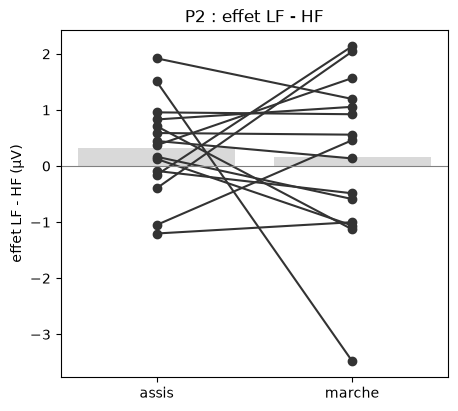

Effet assis : +0.32 µV, t(14) = 1.44, p = 0.171
Effet marche : +0.16 µV, t(14) = 0.41, p = 0.691
Interaction (marche - assis) : -0.16 µV, t(14) = -0.34, p = 0.737, dz = -0.09


In [16]:
# ---- F7 : l'effet dans chaque posture et l'interaction ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.bar([0, 1], interaction.mean(), color='0.85')
ax.plot([0, 1], interaction.T.to_numpy(), color='0.2', marker='o')     # un trait par participant
ax.axhline(0, color='0.5', lw=0.8)
ax.set(xticks=[0, 1], xticklabels=['assis', 'marche'], ylabel=f'effet {NOM_EFFET} (µV)', title=f'{NOM} : effet {NOM_EFFET}')
plt.show()
n = len(interaction)
for posture in ('assis', 'marche'):                              # chaque effet contre 0
    t, p = stats.ttest_1samp(interaction[posture], 0.0)
    print(f'Effet {posture} : {interaction[posture].mean():+.2f} µV, t({n - 1}) = {t:.2f}, p = {p:.3f}')
t, p = stats.ttest_rel(interaction['marche'], interaction['assis'])   # l'interaction : l'effet change-t-il avec la posture ?
difference = interaction['marche'] - interaction['assis']
print(f'Interaction (marche - assis) : {difference.mean():+.2f} µV, t({n - 1}) = {t:.2f}, p = {p:.3f}, '
      f'dz = {difference.mean() / difference.std(ddof=1):.2f}')

*L'effet de fréquence change-t-il avec la posture ?*

## 6. EEG et comportement

Chaque point est un participant : par défaut, son effet sur le TR (axe horizontal) et son effet sur l'amplitude (axe vertical), selon
`COMPORTEMENT`, `MESURE_EEG` et `VALEURS` (section 0.4). Avec peu de participants, cette analyse reste exploratoire.

In [17]:
# ---- 6.1 Le comportement et l'EEG de chaque participant --------------------------------------------------------------------------
large_c = comport.pivot(index='participant', columns='condition', values=COMPORTEMENT)
large_e = mesures_eeg.pivot(index='participant', columns='condition', values=MESURE_EEG)
if VALEURS == 'difference':
    x, y = large_c[COND_B] - large_c[COND_A], large_e[COND_B] - large_e[COND_A]   # l'effet de chaque participant
else:
    x, y = large_c[VALEURS], large_e[VALEURS]                                     # les valeurs d'une condition
points = pd.DataFrame({'comportement': x, 'eeg': y}).dropna()                     # les participants qui ont les deux
points.round(2)

,comportement,eeg
participant,,
P002,19.11,0.74
P003,19.46,0.31
P004,-1.45,-3.83
P006,-6.08,0.37
P007,55.20,0.44
P008,-69.84,-0.09
P009,-22.16,-0.80
P010,85.56,-1.10
P012,4.96,0.25


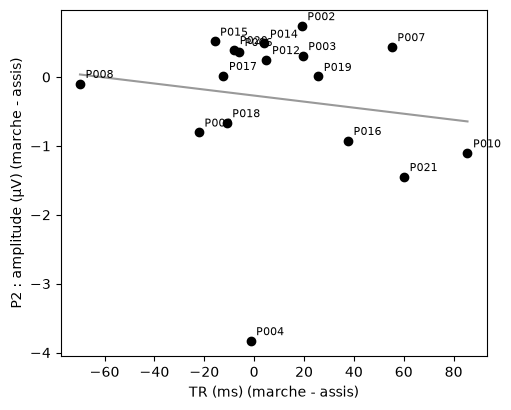

Pearson : r = -0.14, p = 0.584 (n = 17)


In [18]:
# ---- F8 : le nuage de points -----------------------------------------------------------------------------------------------------
r, p = stats.pearsonr(points['comportement'], points['eeg'])
pente, ordonnee = np.polyfit(points['comportement'], points['eeg'], 1)            # la droite qui passe au mieux par les points
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(points['comportement'], points['eeg'], color='k')
for participant, ligne in points.iterrows():
    ax.annotate(participant, (ligne['comportement'], ligne['eeg']), fontsize=8, xytext=(4, 4), textcoords='offset points')
xs = np.array([points['comportement'].min(), points['comportement'].max()])
ax.plot(xs, pente * xs + ordonnee, color='0.6')
suffixe = f' ({COND_B} - {COND_A})' if VALEURS == 'difference' else f' ({VALEURS})'
ax.set(xlabel=COMPORTEMENT + suffixe, ylabel=f'{NOM} : {MESURE_EEG}' + suffixe)
plt.show()
print(f'Pearson : r = {r:.2f}, p = {p:.3f} (n = {len(points)})')

*L'amplitude EEG est-elle liée au comportement ?*

## 7. À retenir

- Énoncez votre hypothèse et vos prédictions (comportement, composante, sens de l'effet) avant de présenter les résultats.
- Pour chaque test, rapportez la moyenne de chaque condition, t(ddl), p, dz et le nombre de participants.
- Refaites l'analyse avec les autres hypothèses et composantes. Pour la LPC, comparez avec `SANS_CLIGNEMENT = True` et avec `'LPC (mot)'`.
- Discutez les limites : le petit nombre de participants, les tests non corrigés (instant par instant et électrode par électrode), la
  fragilité de la latence du pic, les clignements autour de la tape, les mauvaises électrodes et la qualité du signal en marche.

Le notebook 10 analyse les rythmes de l'EEG et le notebook 11 l'apprentissage machine, à partir des fichiers du pipeline Brain Walk
(dossier `pretraite/`).

### Références

- Kutas, M., & Federmeier, K. D. (2011). Thirty years and counting: Finding meaning in the N400 component of the event-related brain potential (ERP). *Annual Review of Psychology, 62*, 621-647. https://doi.org/10.1146/annurev.psych.093008.131123
- Luck, S. J., Stewart, A. X., Simmons, A. M., & Rhemtulla, M. (2021). Standardized measurement error: A universal metric of data quality for averaged event-related potentials. *Psychophysiology, 58*, e13793. https://doi.org/10.1111/psyp.13793
- Maris, E., & Oostenveld, R. (2007). Nonparametric statistical testing of EEG- and MEG-data. *Journal of Neuroscience Methods, 164*, 177-190. https://doi.org/10.1016/j.jneumeth.2007.03.024
- Twomey, D. M., Murphy, P. R., Kelly, S. P., & O'Connell, R. G. (2015). The classic P300 encodes a build-to-threshold decision variable. *European Journal of Neuroscience, 42*, 1636-1643. https://doi.org/10.1111/ejn.12936